In [53]:
import pandas as pd    
import json
import matplotlib.pyplot as plt
import sys
import os
import importlib
import subprocess

sys.path.append('../utils/')
from vllm_server import *
from notebook_utils import *
import vllm_server
import notebook_utils

importlib.reload(vllm_server)
importlib.reload(notebook_utils)


<module 'notebook_utils' from '/home/p316289/Desktop/work/dl-mig-contention-aware-system/experiments/notebooks/../utils/notebook_utils.py'>

In [71]:
EXP_RESULTS_PATH="../results/"
EXP_NAME="vllm_group_size_sweep"
EXP_CPU_OFFLOAD_FLAG="_cpuoffload-on"
EXP_ARTIFACTS_TAR="artifacts.tar.gz" # Not used in this experiment
EXP_METADATA="run_metadata.json"
EXP_METRICS="system_metrics.tar.gz"
SCHEDULER_LOGS="server_results.tar.gz"

In [72]:
# Work on Latest Exp, unless stated otherwise
EXP_PATH_PRE=EXP_RESULTS_PATH + EXP_NAME + EXP_CPU_OFFLOAD_FLAG

latest_exp_dir = get_latest_experiment_dir(EXP_RESULTS_PATH, EXP_PATH_PRE)

if latest_exp_dir:
    print(f"Latest experiment directory: {latest_exp_dir}")
else:
    print("No matching experiment directory found.")

Latest experiment directory: ../results/../results/vllm_group_size_sweep_cpuoffload-on_20261012T163533


In [73]:
# Print experiment metadata
with open(f"{latest_exp_dir}/{EXP_METADATA}", 'r') as f:
    metadata = json.load(f)
    print(json.dumps(metadata, indent=2))

{
  "burst_ticks": 0,
  "continue_on_failure": false,
  "cpu_offload_by_model": {
    "Qwen/Qwen2.5-1.5B-Instruct": "0.2",
    "Qwen/Qwen2.5-VL-3B-Instruct-AWQ": "0.2",
    "RedHatAI/SmolLM-1.7B-Instruct-quantized.w8a16": "0.2",
    "RedHatAI/gemma-2-2b-it-quantized.w4a16": "0.1"
  },
  "cpu_offload_enabled": true,
  "git_commit": "5e285c86c69dd9858423b2164da3d37699f288a0",
  "group_size_values": [
    2
  ],
  "include_baseline": false,
  "libcuda_log_level": "2",
  "models": [
    "RedHatAI/gemma-2-2b-it-quantized.w4a16",
    "RedHatAI/SmolLM-1.7B-Instruct-quantized.w8a16",
    "Qwen/Qwen2.5-1.5B-Instruct",
    "Qwen/Qwen2.5-VL-3B-Instruct-AWQ"
  ],
  "rate_control_worker_id": 1,
  "request_count": [
    "200"
  ],
  "request_rate": [
    "10"
  ],
  "run_id": "vllm_group_size_sweep_cpuoffload-on_20261012T163533",
  "timestamp": "20261012T163533",
  "vllm_extra_args": [
    "--tensor-parallel-size",
    "1",
    "--max-model-len",
    "1024",
    "--async-scheduling",
    "--limit-mm

In [74]:
# Extract artifacts and system metrics
data_dict = {}
for rps in metadata['request_rate']:
    for nrq in metadata['request_count']:
        for model in metadata['models']:
            data_dict[model] = {}
            model_path_name = model.replace('/', '_')
            for gb_settings in metadata['group_size_values']:
                data_dict[model][gb_settings] = {}
                dest = f"/tmp/{str(latest_exp_dir).split('/')[-1]}/{model_path_name}/group-size-{gb_settings}"
                if not os.path.exists(dest):
                    os.makedirs(dest, exist_ok=True)

                if os.path.isfile(f"{latest_exp_dir}/{model_path_name}/group-size-{gb_settings}/{EXP_ARTIFACTS_TAR}"):
                    subprocess.run(["tar", "-xf", f"{latest_exp_dir}/{model_path_name}/group-size-{gb_settings}/{EXP_ARTIFACTS_TAR}", "-C", dest])
                    data_dict[model][gb_settings][EXP_ARTIFACTS_TAR] = f"{dest}/artifacts/group-size-{gb_settings}/{model_path_name}_rps{rps}_n{nrq}/group-size-{gb_settings}.csv"

                if os.path.isfile(f"{latest_exp_dir}/{model_path_name}/group-size-{gb_settings}/{EXP_METRICS}"):
                    subprocess.run(["tar", "-xf", f"{latest_exp_dir}/{model_path_name}/group-size-{gb_settings}/{EXP_METRICS}", "-C", dest])
                    data_dict[model][gb_settings][EXP_METRICS] = f"{dest}/group-size-{gb_settings}__{model_path_name}_rps{rps}_n{nrq}.csv"

                if os.path.isfile(f"{latest_exp_dir}/{model_path_name}/group-size-{gb_settings}/{SCHEDULER_LOGS}"):
                    subprocess.run(["tar", "-xf", f"{latest_exp_dir}/{model_path_name}/group-size-{gb_settings}/{SCHEDULER_LOGS}", "-C", dest])
                    data_dict[model][gb_settings][SCHEDULER_LOGS] = f"{dest}/scheduler.csv"

In [75]:
results = []
for model in metadata['models']:
    for gb_settings in metadata['group_size_values']:
        if EXP_ARTIFACTS_TAR in data_dict[model][gb_settings].keys():
            df = read_summary_report(data_dict[model][gb_settings][EXP_ARTIFACTS_TAR])
            results.append({
                "Model": model,
                "Group Size": gb_settings,
                "Request Throughput": df.loc[df["Metric"] == "Request Throughput (requests/sec)", "Value"].item(),
                "Output Token Throughput": (
                    df.loc[df["Metric"] == "Output Token Throughput (tokens/sec)", "Value"].item()
                ),
            })
results_df = pd.DataFrame(results)

In [76]:
results_df

,Model,Group Size,Request Throughput,Output Token Throughput
0,RedHatAI/gemma-2-2b-it-quantized.w4a16,2,0.63,280.53
1,RedHatAI/SmolLM-1.7B-Instruct-quantized.w8a16,2,0.83,194.17
2,Qwen/Qwen2.5-1.5B-Instruct,2,1.89,346.22
3,Qwen/Qwen2.5-VL-3B-Instruct-AWQ,2,2.58,541.48


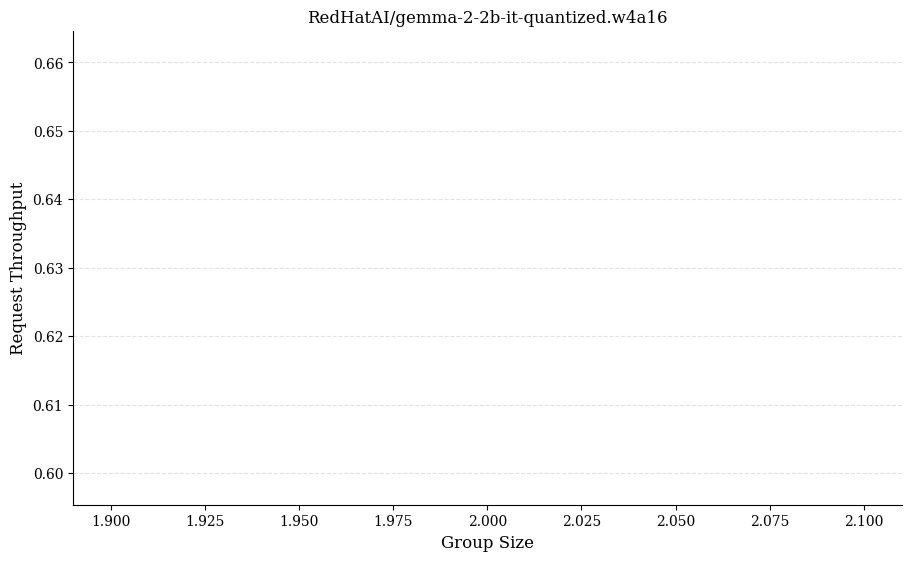

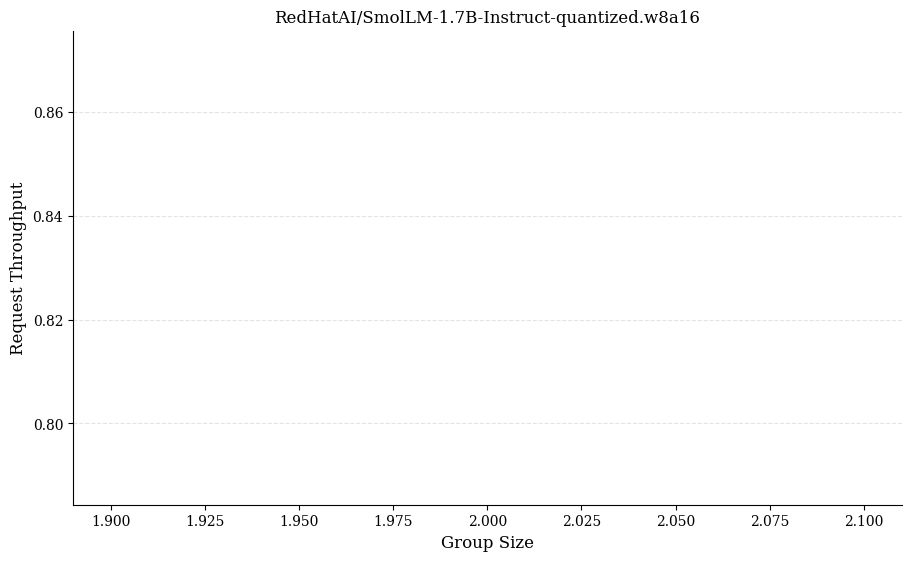

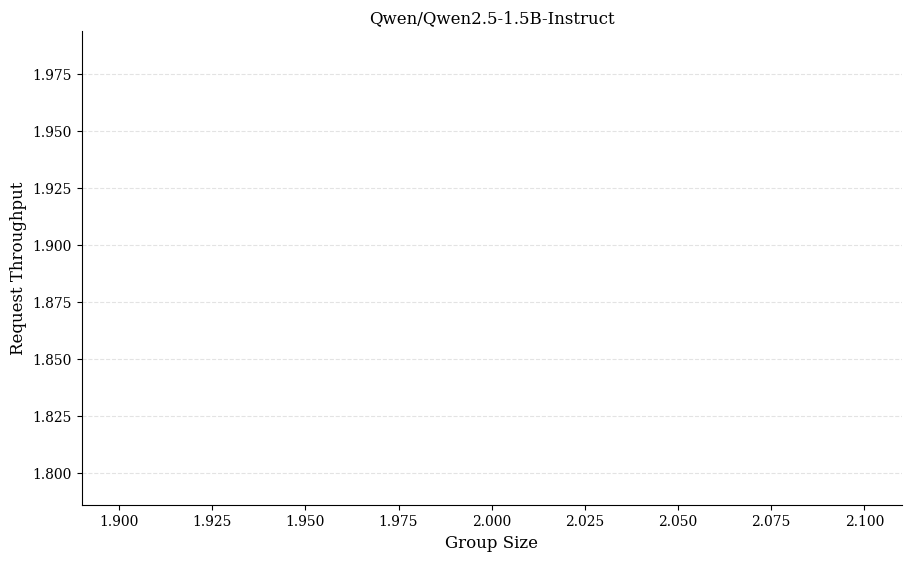

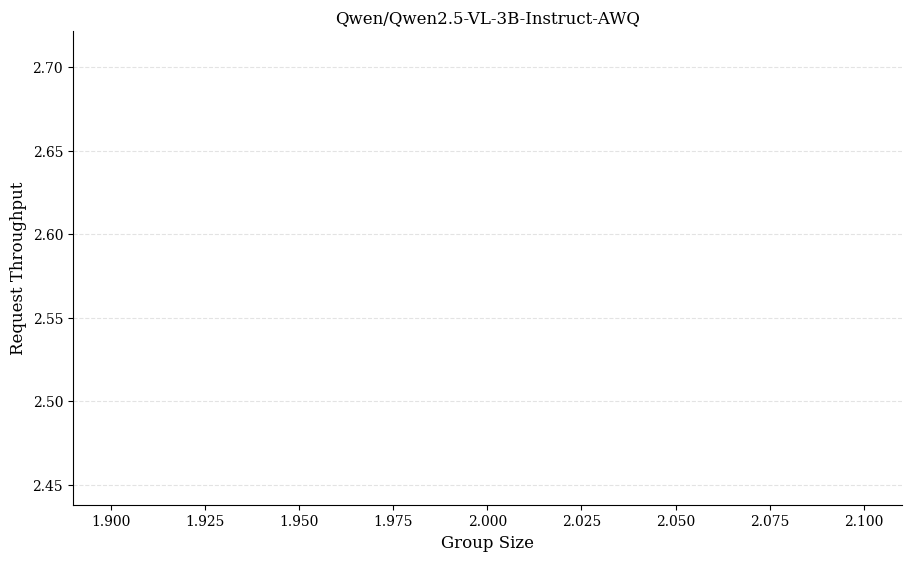

In [77]:
for model in results_df["Model"].unique():
    fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
    X = results_df.loc[results_df["Model"] == model, "Group Size"].to_numpy()
    Y = results_df.loc[results_df["Model"] == model, "Request Throughput"].to_numpy()
    ax.plot(X, Y)
    ax.set_xlabel("Group Size")
    ax.set_ylabel("Request Throughput")
    ax.set_title(f"{model}")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

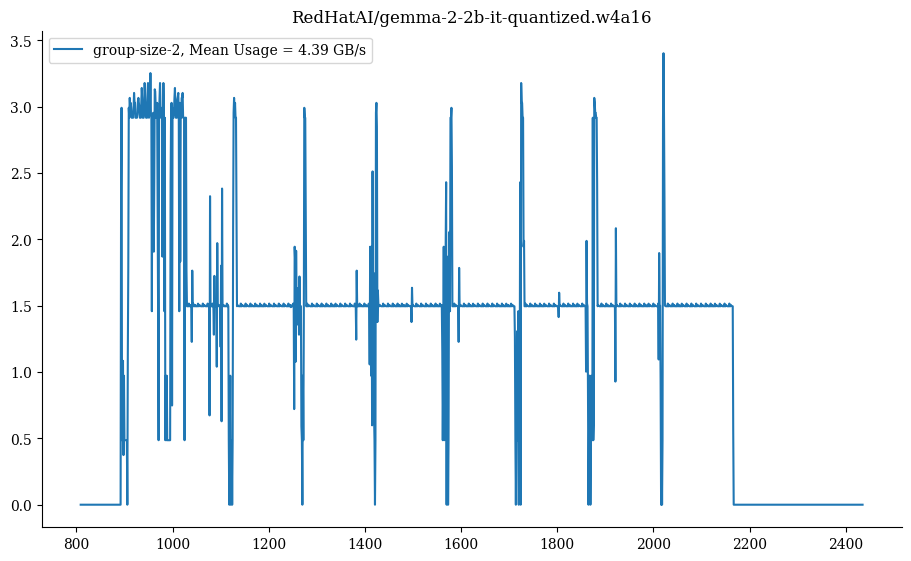

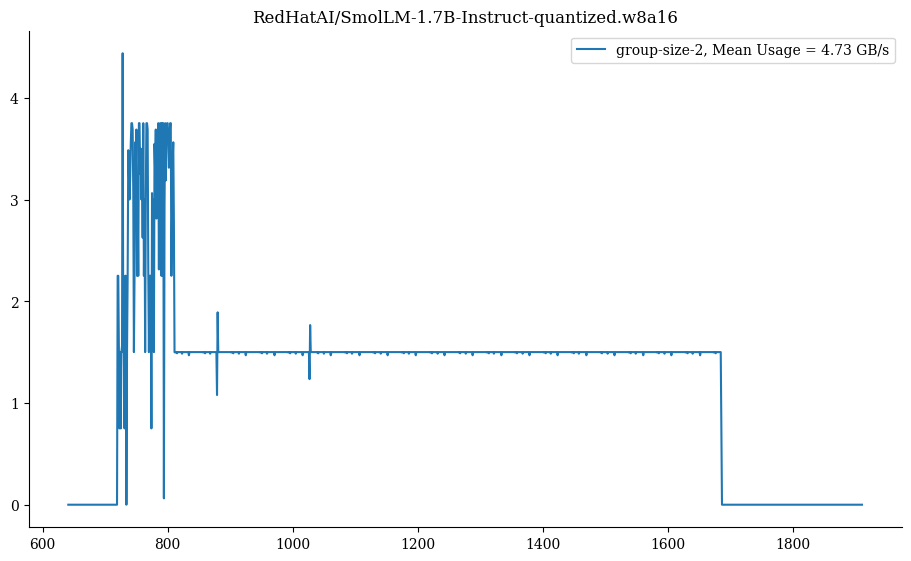

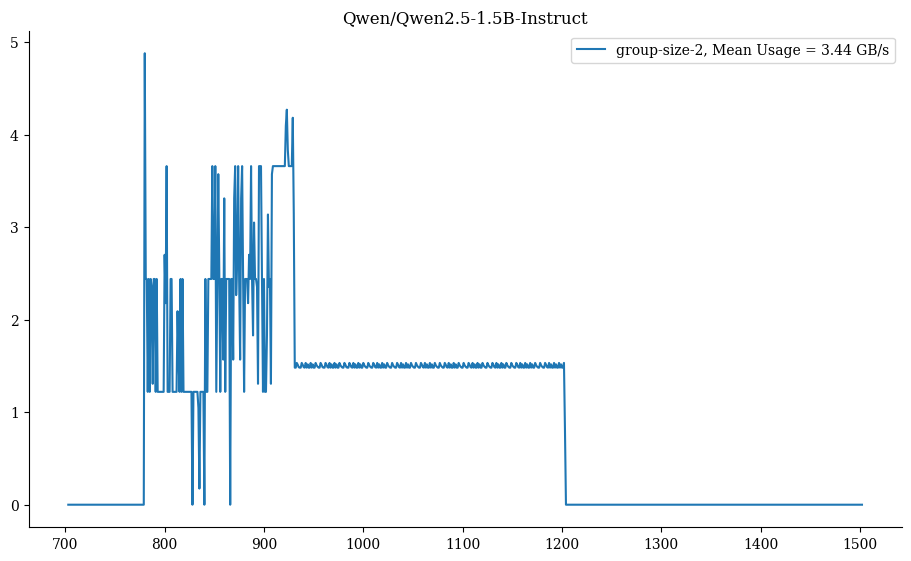

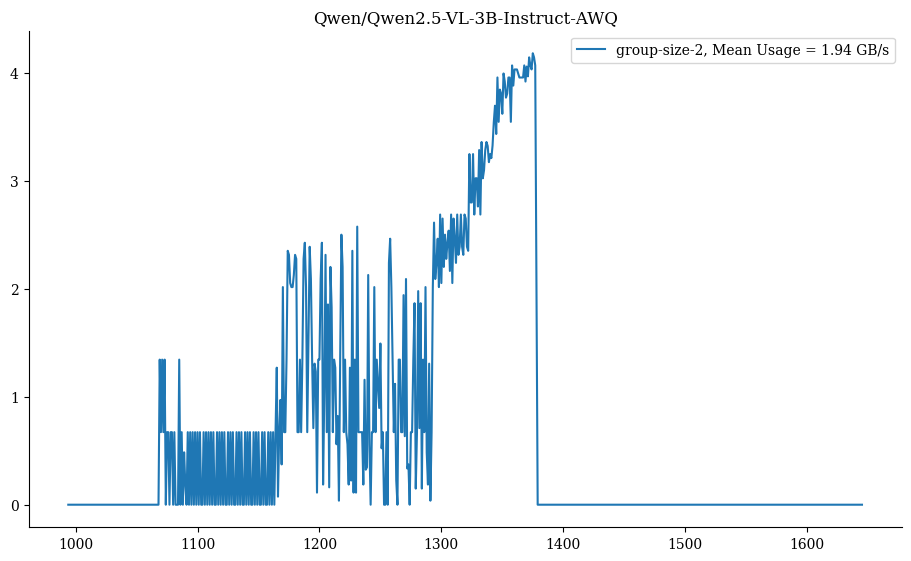

In [80]:
for model in metadata['models']:
    fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
    for gb_settings in metadata['group_size_values']:
        if SCHEDULER_LOGS in data_dict[model][gb_settings].keys():
            df = pd.read_csv(data_dict[model][gb_settings][SCHEDULER_LOGS])
            t0 = df.loc[df["usage_bytes"] != 0, "tick"].min()
            tf = df.loc[df["usage_bytes"] != 0, "tick"].max()
            mean = df.loc[(df["tick"] >= t0) & (df["tick"] <= tf), "usage_bytes"].mean()  / (1024 * 1024 * 1024) / 0.25
            df = df[df["phase"] == "limit"]
            df["usage_bytes"] = df["usage_bytes"] / (1024 * 1024 * 1024)
            X = df["tick"].to_numpy()
            Y = df["usage_bytes"].to_numpy()
            Y1 = df["buckets"].to_numpy()
            ax.plot(X, Y, label=f"group-size-{gb_settings}, Mean Usage = {mean:.2f} GB/s")
            #ax.plot(X, Y1, label=f"group-size-{gb_settings}", linestyle='dotted')
            ax.legend()
            ax.set_title(f"{model}")
            if gb_settings == 2 and model == "RedHatAI/gemma-2-2b-it-quantized.w4a16":
                df_monitor = pd.read_csv(data_dict[model][gb_settings][SCHEDULER_LOGS])

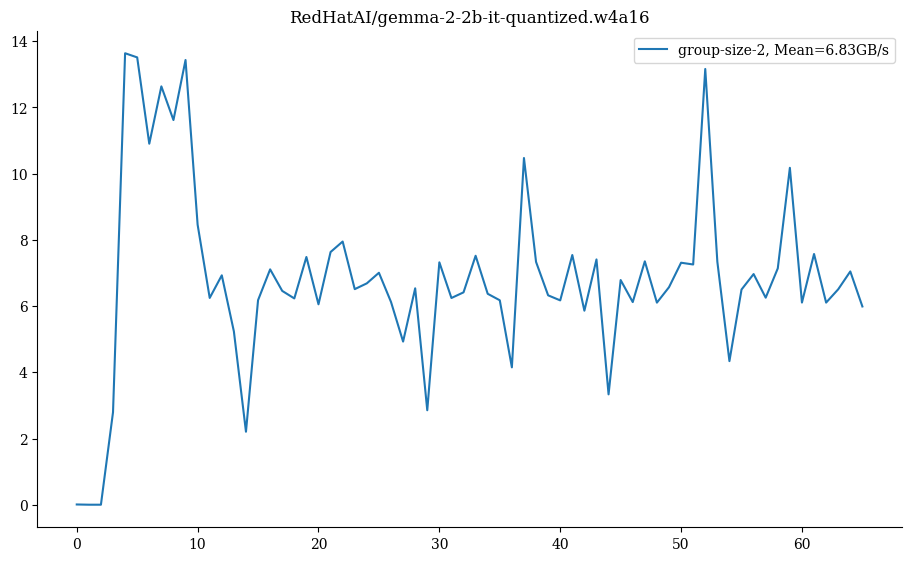

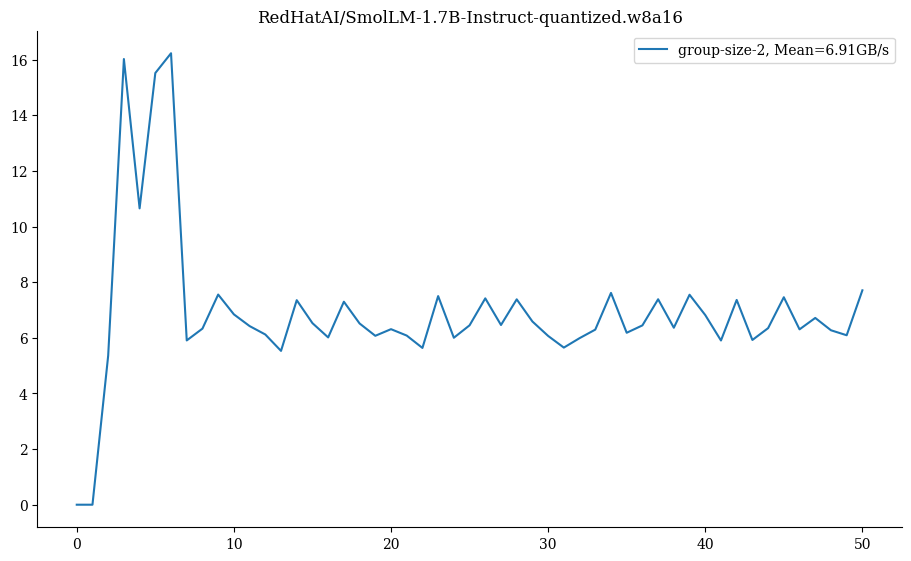

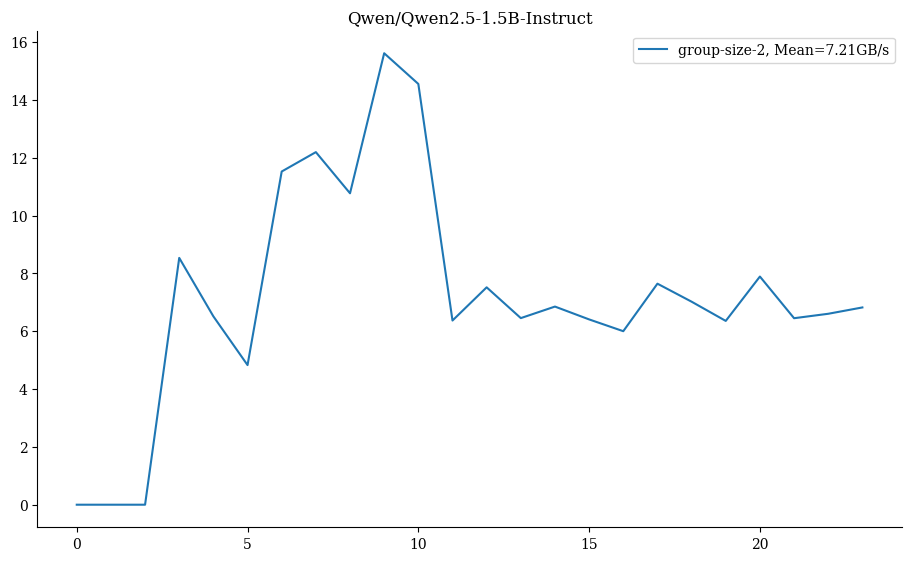

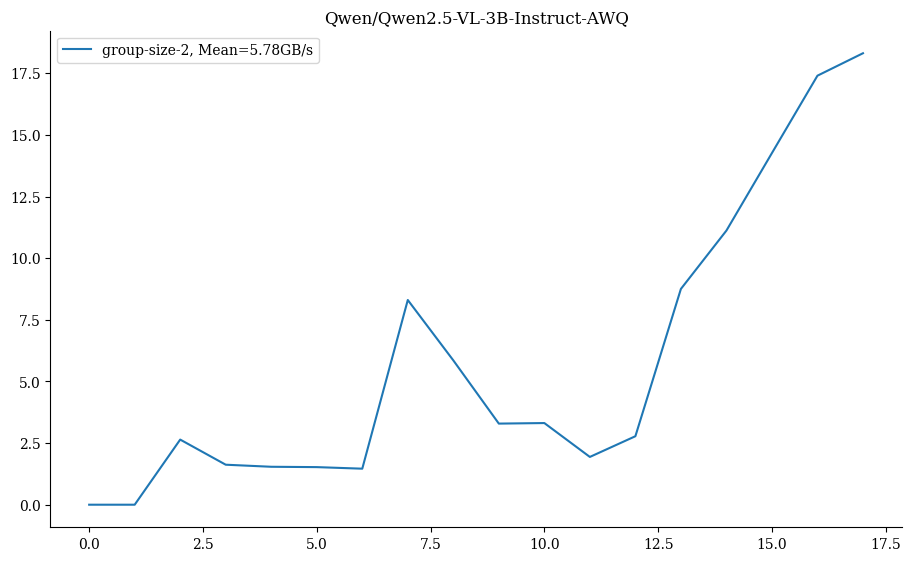

In [81]:
for model in metadata['models']:
    fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
    for gb_settings in metadata['group_size_values']:
        if EXP_METRICS in data_dict[model][gb_settings].keys():
            df = pd.read_csv(data_dict[model][gb_settings][EXP_METRICS])
            df = df[df["metric"] == "DCGM_FI_PROF_PCIE_RX_BYTES"]
            df["value"] = df["value"] / (1024 * 1024 * 1024)
            Y = df["value"].to_numpy()
            ax.plot(Y, label=f"group-size-{gb_settings}, Mean={df["value"].mean():.2f}GB/s")
            #ax.plot(X, Y1, label=f"group-size-{gb_settings}", linestyle='dotted')
            ax.legend()
            ax.set_title(f"{model}")
            if gb_settings == 2 and model == "RedHatAI/gemma-2-2b-it-quantized.w4a16":
                df_raw = df



/tmp/ipykernel_8455/3148651475.py:7: FutureWarning: A grouping was used that is not in the columns of the DataFrame and so was excluded from the result. This grouping will be included in a future version of pandas. Add the grouping as a column of the DataFrame to silence this warning.
  .agg(


<Axes: xlabel='timestamp'>

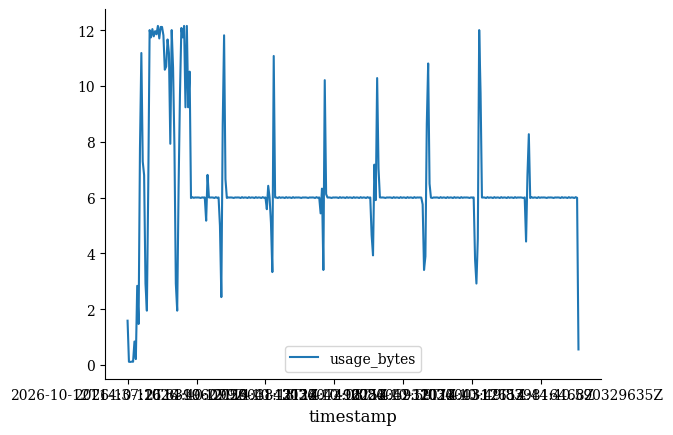

In [82]:
df_monitor = df_monitor.loc[df_monitor["usage_bytes"].ne(0)].reset_index(drop=True)

group_id = df_monitor.index // 4

df_grouped = (
    df_monitor.groupby(group_id, as_index=False)
    .agg(
        timestamp=("timestamp", "first"),
        usage_bytes=("usage_bytes", "sum"),
    )
)

df_grouped.to_csv("tmp.csv", index=False)
df_grouped["usage_bytes"] = df_grouped["usage_bytes"] / (1024 * 1024 * 1024)
df_grouped.plot(x="timestamp", y="usage_bytes")

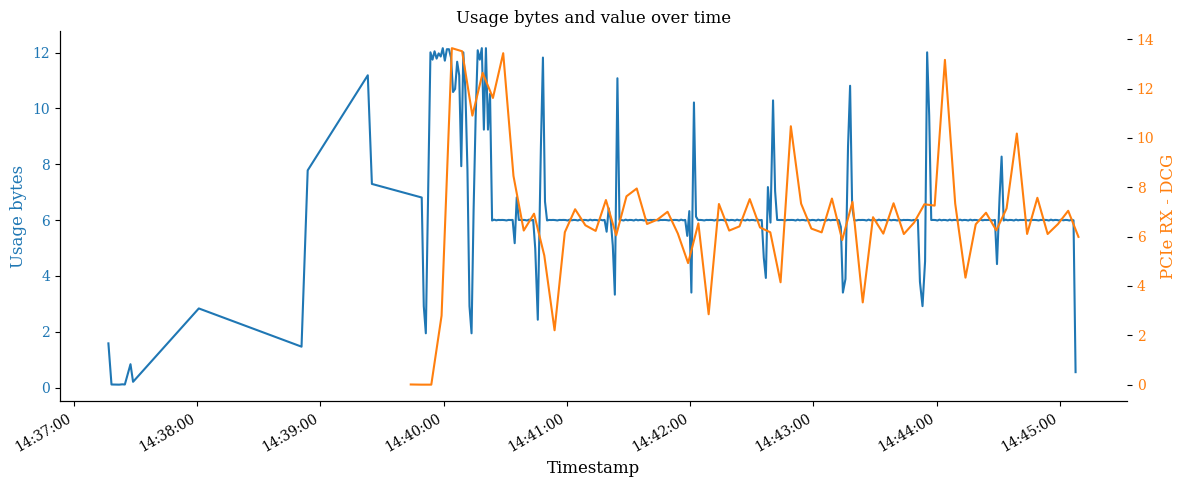

In [83]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    pd.to_datetime(df_grouped["timestamp"]),
    df_grouped["usage_bytes"],
    label="usage_bytes-Scheduler",
    color="tab:blue",
)
ax1.set_ylabel("Usage bytes", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(
    pd.to_datetime(df_raw["timestamp"]),
    df_raw["value"],
    label="PCIe RX - DCGM",
    color="tab:orange",
)
ax2.set_ylabel("PCIe RX - DCG", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

ax1.set_xlabel("Timestamp")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
fig.autofmt_xdate()
plt.title("Usage bytes and value over time")
plt.tight_layout()
plt.show()

In [84]:
df_monitor.to_csv("tmp.csv", index=False)